# Copenhagen Airport Metro Station — Exploratory Analysis

**Station:** Københavns Lufthavn · **ID:** 8603328 · **Line:** M1/M2  
**Data period:** 2024-04-01 → 2026-03-31

---

## What this notebook does

This notebook performs a full exploratory data analysis (EDA) of passenger flow at the Copenhagen Airport metro station. The goal is to understand:

- The overall shape of `ins` (arrivals from airport → city) and `outs` (departures city → airport)
- Daily, hourly, and weekly patterns
- Seasonal variation across months
- Anomalous days that stand out from the norm
- The balance between arrivals and departures over time

All 14 plots are saved to `output_plots/`.

## 1. Imports and Configuration

We use:
- `pandas` and `numpy` for data manipulation
- `matplotlib` and `seaborn` for plotting
- `scipy.stats` for z-score outlier detection
- `MetroDataQuery` — a shared utility in `DatabaseScripts/` that reads the parquet file in batches and supports chainable filters

In [1]:
from __future__ import annotations

from pathlib import Path
import sys
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from scipy import stats

# Resolve root so imports work regardless of where the notebook is opened
ROOT = Path().resolve().parents[1]
sys.path.append(str(ROOT / "DatabaseScripts"))

from DataFilter import MetroDataQuery

PARQUET_PATH = ROOT / "metro_passengers.parquet"
STATION_ID   = 8603328
OUT_DIR      = Path().resolve() / "output_plots"
OUT_DIR.mkdir(exist_ok=True)

try:
    plt.style.use("seaborn-v0_8-whitegrid")
except OSError:
    plt.style.use("seaborn-whitegrid")

BLUE   = "#2878B5"
ORANGE = "#FF7F0E"
GREY   = "#AAAAAA"
DPI    = 150

WEEKDAY_ORDER = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
MONTH_NAMES   = ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
                 "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

def save(fig: plt.Figure, name: str) -> None:
    path = OUT_DIR / name
    fig.tight_layout()
    fig.savefig(path, dpi=DPI)
    print(f"  saved → {path.name}")

## 2. Load Data

`MetroDataQuery` reads the shared parquet file and returns only rows for:
- Station ID `8603328` (Københavns Lufthavn)
- System `m1m2` (the M1/M2 metro lines that serve the airport)

The raw data is at **1-minute resolution** with one row per minute per gate.

In [2]:
query = (
    MetroDataQuery(PARQUET_PATH)
    .filter_station_id(STATION_ID)
    .filter_system("m1m2")
)

df = query.to_pandas(sort_by_time=True)
print(f"Raw shape: {df.shape}")
df.head()

Raw shape: (1051200, 7)


,timestamp,stationId,system,station,ins,outs,passengerNo
0,2024-04-01 00:00:00+00:00,8603328,m1m2,Københavns Lufthavn,33.000000000,5.000000000,19.000000000
1,2024-04-01 00:01:00+00:00,8603328,m1m2,Københavns Lufthavn,29.000000000,2.000000000,15.500000000
2,2024-04-01 00:02:00+00:00,8603328,m1m2,Københavns Lufthavn,35.000000000,5.000000000,20.000000000
3,2024-04-01 00:03:00+00:00,8603328,m1m2,Københavns Lufthavn,22.000000000,4.000000000,13.000000000
4,2024-04-01 00:04:00+00:00,8603328,m1m2,Københavns Lufthavn,20.000000000,13.000000000,16.500000000


## 3. Preprocessing

Steps:
1. Cast `ins`, `outs`, `passengerNo` to numeric (coerce any non-numeric to 0).
2. Parse `timestamp` as UTC-aware datetime.
3. Derive calendar features: `date`, `hour`, `weekday`, `month`, `year`, `week`, `is_weekend`.
4. Compute `net_flow = ins − outs` (positive = more arrivals, negative = more departures).
5. **Drop zero-activity rows** — these occur at night when no passengers pass through. They add noise to averages without carrying information.

### Variable meaning at the airport station

| Variable | Meaning |
|---|---|
| `ins` | Passengers entering the metro station **from** the airport — just landed, heading to city |
| `outs` | Passengers exiting the metro station **at** the airport — departing by flight |
| `passengerNo` | Exactly `(ins + outs) / 2` — adds no new information, verified across all 1M+ rows |

In [3]:
for col in ["ins", "outs", "passengerNo"]:
    df[col] = pd.to_numeric(df[col], errors="coerce").fillna(0.0)

df["timestamp"] = pd.to_datetime(df["timestamp"], utc=True)
df["date"]       = df["timestamp"].dt.date
df["hour"]       = df["timestamp"].dt.hour
df["weekday"]    = df["timestamp"].dt.day_name()
df["month"]      = df["timestamp"].dt.month
df["year"]       = df["timestamp"].dt.year
df["week"]       = df["timestamp"].dt.isocalendar().week.astype(int)
df["is_weekend"] = df["timestamp"].dt.dayofweek >= 5
df["net_flow"]   = df["ins"] - df["outs"]

zero_rows = int(((df["ins"] == 0) & (df["outs"] == 0)).sum())
df = df[(df["ins"] > 0) | (df["outs"] > 0)].copy()

print(f"Shape after cleaning : {df.shape}")
print(f"Zero-activity rows removed: {zero_rows:,}")
print(f"Date range: {df['timestamp'].min().date()} → {df['timestamp'].max().date()}")
df[["timestamp", "ins", "outs", "net_flow", "hour", "weekday"]].head(10)

Shape after cleaning : (913540, 15)
Zero-activity rows removed: 137,660
Date range: 2024-04-01 → 2026-03-31


,timestamp,ins,outs,net_flow,hour,weekday
0,2024-04-01 00:00:00+00:00,33.0,5.0,28.0,0,Monday
1,2024-04-01 00:01:00+00:00,29.0,2.0,27.0,0,Monday
2,2024-04-01 00:02:00+00:00,35.0,5.0,30.0,0,Monday
3,2024-04-01 00:03:00+00:00,22.0,4.0,18.0,0,Monday
4,2024-04-01 00:04:00+00:00,20.0,13.0,7.0,0,Monday
5,2024-04-01 00:05:00+00:00,30.0,13.0,17.0,0,Monday
6,2024-04-01 00:06:00+00:00,27.0,7.0,20.0,0,Monday
7,2024-04-01 00:07:00+00:00,38.0,3.0,35.0,0,Monday
8,2024-04-01 00:08:00+00:00,25.0,3.0,22.0,0,Monday
9,2024-04-01 00:09:00+00:00,29.0,3.0,26.0,0,Monday


## 4. Summary Statistics

A quick numerical overview before any plotting.

Key things to notice:
- `outs` has a **much higher standard deviation** than `ins` — departures are burstier (many passengers arrive at the airport just before flight waves).
- The peak hours and busiest weekday align with real-world airport behavior.

In [4]:
print("=" * 58)
print("  AIRPORT STATION SUMMARY (Københavns Lufthavn)")
print("=" * 58)
print(f"  Total observations     : {len(df):,}")
print(f"  Date range             : {df['timestamp'].min().date()} to {df['timestamp'].max().date()}")
print(f"  Total ins              : {df['ins'].sum():,.0f}")
print(f"  Total outs             : {df['outs'].sum():,.0f}")
print(f"  Mean ins per obs       : {df['ins'].mean():.2f}")
print(f"  Mean outs per obs      : {df['outs'].mean():.2f}")
print(f"  Peak hour (ins)        : {int(df.groupby('hour')['ins'].mean().idxmax()):02d}:00")
print(f"  Peak hour (outs)       : {int(df.groupby('hour')['outs'].mean().idxmax()):02d}:00")
print(f"  Busiest weekday (ins)  : {df.groupby('weekday')['ins'].mean().idxmax()}")
print(f"  Busiest month (ins)    : {MONTH_NAMES[int(df.groupby('month')['ins'].mean().idxmax()) - 1]}")
print(f"  Zero-activity rows     : {zero_rows:,}")
print("=" * 58)

df[["ins", "outs", "net_flow"]].describe()

  AIRPORT STATION SUMMARY (Københavns Lufthavn)
  Total observations     : 913,540
  Date range             : 2024-04-01 to 2026-03-31
  Total ins              : 9,209,543
  Total outs             : 10,611,841
  Mean ins per obs       : 10.08
  Mean outs per obs      : 11.62
  Peak hour (ins)        : 17:00
  Peak hour (outs)       : 16:00
  Busiest weekday (ins)  : Friday
  Busiest month (ins)    : Aug
  Zero-activity rows     : 137,660


,ins,outs,net_flow
count,913540.000000,913540.000000,913540.000000
mean,10.081160,11.616176,-1.535015
std,7.440133,17.417909,18.119475
min,0.000000,0.000000,-178.000000
25%,4.000000,1.000000,-5.000000
50%,9.000000,4.000000,3.000000
75%,14.000000,15.000000,9.000000
max,115.000000,190.000000,105.000000


---

## Plot 01 — Raw Time Series

The full 1-minute resolution time series for `ins`, `outs`, and `passengerNo` over the entire 2-year period.

**What to look for:**
- The overall level and variance of the two flows
- Whether `ins` and `outs` track each other or diverge systematically
- Any obvious anomalies or gaps
- `passengerNo` (dashed grey) sits exactly between the two — confirming it is `(ins + outs) / 2`

  saved → 01_raw_timeseries.png


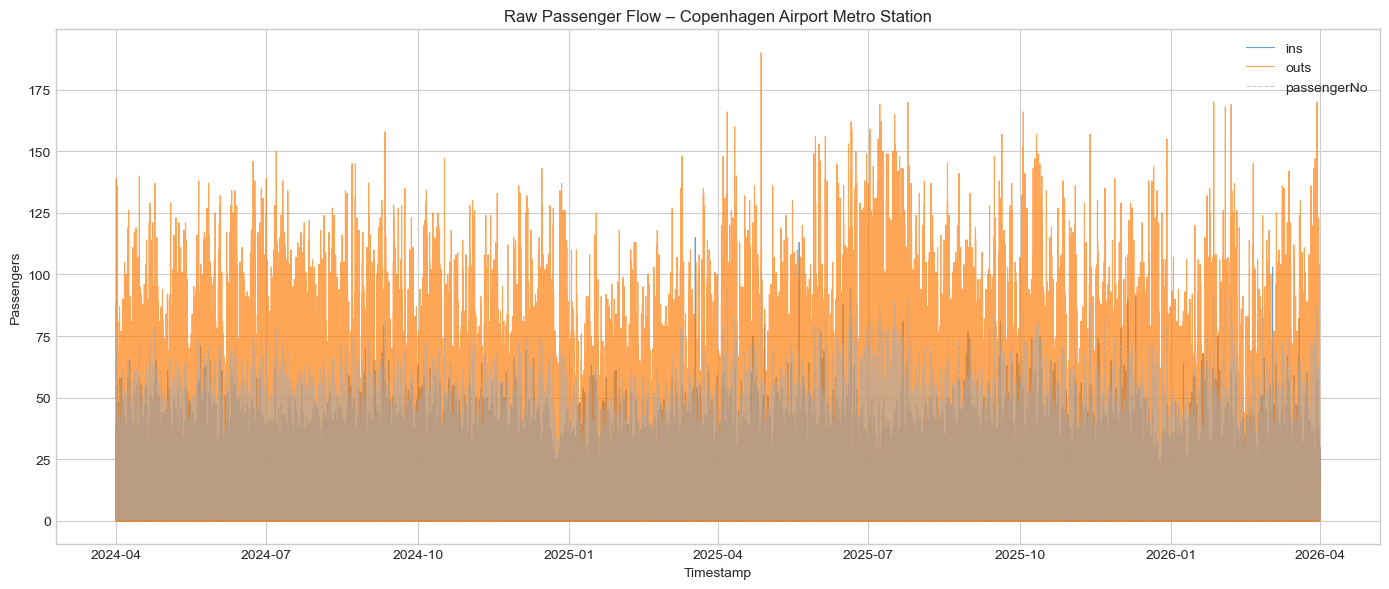

In [5]:
fig, ax = plt.subplots(figsize=(14, 6))
ax.plot(df["timestamp"], df["ins"],         color=BLUE,   alpha=0.7, lw=0.8, label="ins")
ax.plot(df["timestamp"], df["outs"],        color=ORANGE, alpha=0.7, lw=0.8, label="outs")
ax.plot(df["timestamp"], df["passengerNo"], color=GREY,   alpha=0.6, lw=0.8, ls="--", label="passengerNo")
ax.set_title("Raw Passenger Flow – Copenhagen Airport Metro Station")
ax.set_xlabel("Timestamp")
ax.set_ylabel("Passengers")
ax.legend()
save(fig, "01_raw_timeseries.png")
plt.show()

---

## Plot 02 — Daily Aggregated Flow

We resample to **daily totals** to smooth out minute-to-minute noise and reveal the macro trend.

The shaded areas show **which direction dominated each day**:
- **Blue shading**: more arrivals than departures (`ins > outs`)
- **Orange shading**: more departures than arrivals (`outs > ins`)

**What to look for:**
- Summer peaks (July–August) vs. winter troughs
- Whether the airport is consistently departure-dominant or arrival-dominant on certain days
- Any isolated dips (disruptions, strikes, public holidays)

  saved → 02_daily_flow.png


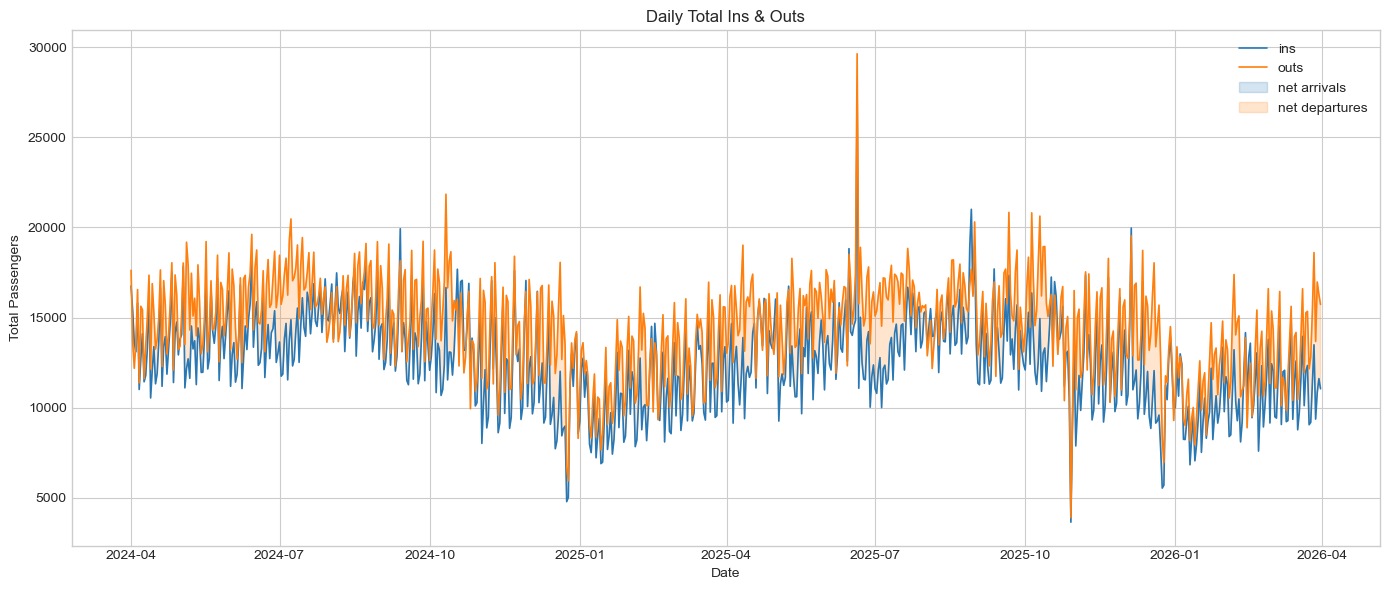

In [6]:
daily = df.set_index("timestamp").resample("D")[["ins", "outs"]].sum()

fig, ax = plt.subplots(figsize=(14, 6))
ax.plot(daily.index, daily["ins"],  color=BLUE,   lw=1.2, label="ins")
ax.plot(daily.index, daily["outs"], color=ORANGE, lw=1.2, label="outs")
ax.fill_between(daily.index, daily["ins"], daily["outs"],
                where=daily["ins"] >= daily["outs"], alpha=0.2, color=BLUE,   label="net arrivals")
ax.fill_between(daily.index, daily["ins"], daily["outs"],
                where=daily["ins"] <  daily["outs"], alpha=0.2, color=ORANGE, label="net departures")
ax.set_title("Daily Total Ins & Outs")
ax.set_xlabel("Date")
ax.set_ylabel("Total Passengers")
ax.legend()
save(fig, "02_daily_flow.png")
plt.show()

---

## Plot 03 — Hourly Profile: Weekday vs Weekend

The average passenger count per **hour of day**, split by weekday vs weekend.

**What to look for:**
- The two `outs` peaks (early morning and mid-afternoon) corresponding to the two main departure waves at CPH
- Whether the weekend profile is shifted or flatter compared to weekdays
- The `ins` peak in the late afternoon — arriving passengers heading into the city after landing

  saved → 03_hourly_profile.png


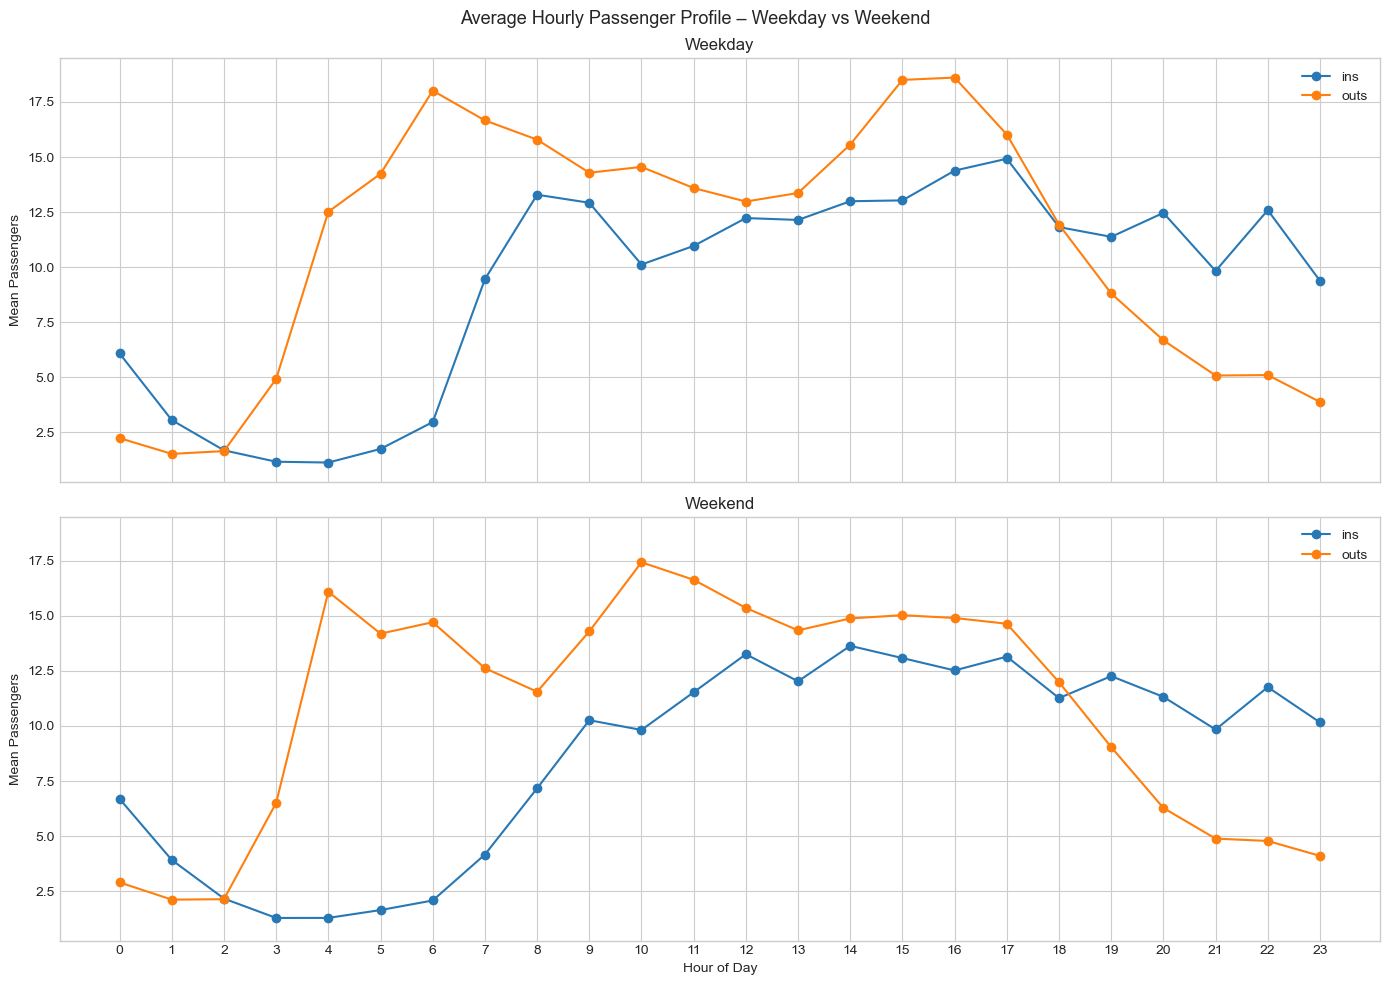

In [7]:
fig, axes = plt.subplots(2, 1, figsize=(14, 10), sharex=True, sharey=True)

for ax, is_wknd, label in zip(axes, [False, True], ["Weekday", "Weekend"]):
    sub = df[df["is_weekend"] == is_wknd].groupby("hour")[["ins", "outs"]].mean()
    ax.plot(sub.index, sub["ins"],  marker="o", color=BLUE,   label="ins")
    ax.plot(sub.index, sub["outs"], marker="o", color=ORANGE, label="outs")
    ax.set_title(label)
    ax.set_ylabel("Mean Passengers")
    ax.legend()
    ax.set_xticks(range(24))

axes[1].set_xlabel("Hour of Day")
fig.suptitle("Average Hourly Passenger Profile – Weekday vs Weekend", fontsize=13)
save(fig, "03_hourly_profile.png")
plt.show()

---

## Plot 04 — Day-of-Week Pattern

Mean `ins` and `outs` grouped by day of week, with **error bars showing standard deviation**.

**What to look for:**
- Friday is typically the busiest day for departures (business travel + start-of-weekend trips)
- Saturday is often quieter for `ins` — people who left Friday aren't yet returning
- Wide error bars mean high day-to-day variability even within the same weekday

  saved → 04_weekday_pattern.png


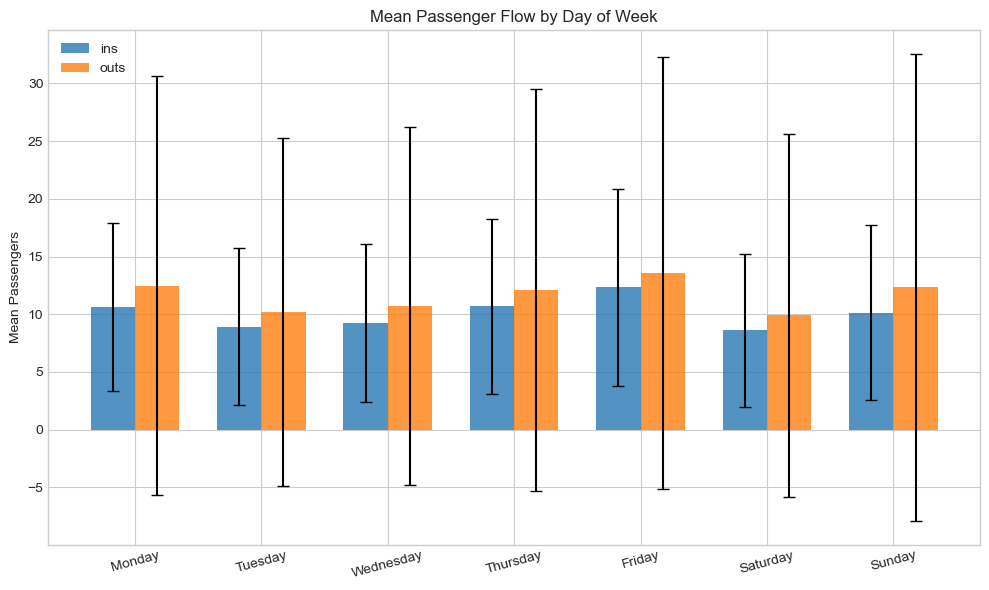

In [8]:
wkd = df.groupby("weekday")[["ins", "outs"]].agg(["mean", "std"]).reindex(WEEKDAY_ORDER)
x   = np.arange(len(WEEKDAY_ORDER))
w   = 0.35

fig, ax = plt.subplots(figsize=(10, 6))
ax.bar(x - w/2, wkd["ins"]["mean"],  w, yerr=wkd["ins"]["std"],  color=BLUE,   alpha=0.8, label="ins",  capsize=4)
ax.bar(x + w/2, wkd["outs"]["mean"], w, yerr=wkd["outs"]["std"], color=ORANGE, alpha=0.8, label="outs", capsize=4)
ax.set_xticks(x)
ax.set_xticklabels(WEEKDAY_ORDER, rotation=15)
ax.set_title("Mean Passenger Flow by Day of Week")
ax.set_ylabel("Mean Passengers")
ax.legend()
save(fig, "04_weekday_pattern.png")
plt.show()

---

## Plot 05 — Monthly Seasonality

Mean `ins` and `outs` per calendar month, with a ±1 std shaded band.

**What to look for:**
- Summer months (July–August) have the highest traffic — holiday season
- January is the quietest month
- The seasonal swing is roughly +46% from January to August
- Whether `ins` and `outs` seasonality are in sync or offset

  saved → 05_monthly_seasonality.png


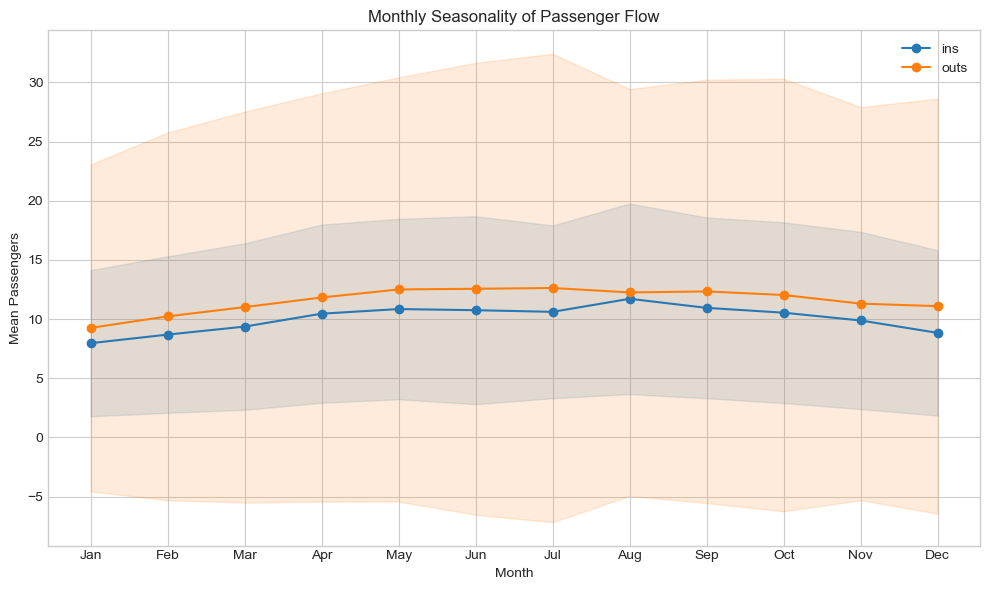

In [9]:
mon = df.groupby("month")[["ins", "outs"]].agg(["mean", "std"])

fig, ax = plt.subplots(figsize=(10, 6))
for col, color in [("ins", BLUE), ("outs", ORANGE)]:
    m = mon[col]["mean"]
    s = mon[col]["std"]
    ax.plot(m.index, m.values, marker="o", color=color, label=col)
    ax.fill_between(m.index, m - s, m + s, color=color, alpha=0.15)

ax.set_xticks(range(1, 13))
ax.set_xticklabels(MONTH_NAMES)
ax.set_title("Monthly Seasonality of Passenger Flow")
ax.set_xlabel("Month")
ax.set_ylabel("Mean Passengers")
ax.legend()
save(fig, "05_monthly_seasonality.png")
plt.show()

---

## Plot 06 — Heatmap: Hour × Weekday

A 2D heatmap of mean `passengerNo` (total activity) for each (hour, weekday) combination.

This condenses the daily and weekly patterns into a single visualization — allowing you to spot exactly **when** the station is busiest across the full week.

**What to look for:**
- The morning departure band (05:00–08:00) vs the afternoon arrival band (15:00–18:00)
- Whether weekends are uniformly different from weekdays or only differ in specific hours
- Any weekday × hour combinations that stand out as unusually quiet or busy

  saved → 06_heatmap_hour_weekday.png


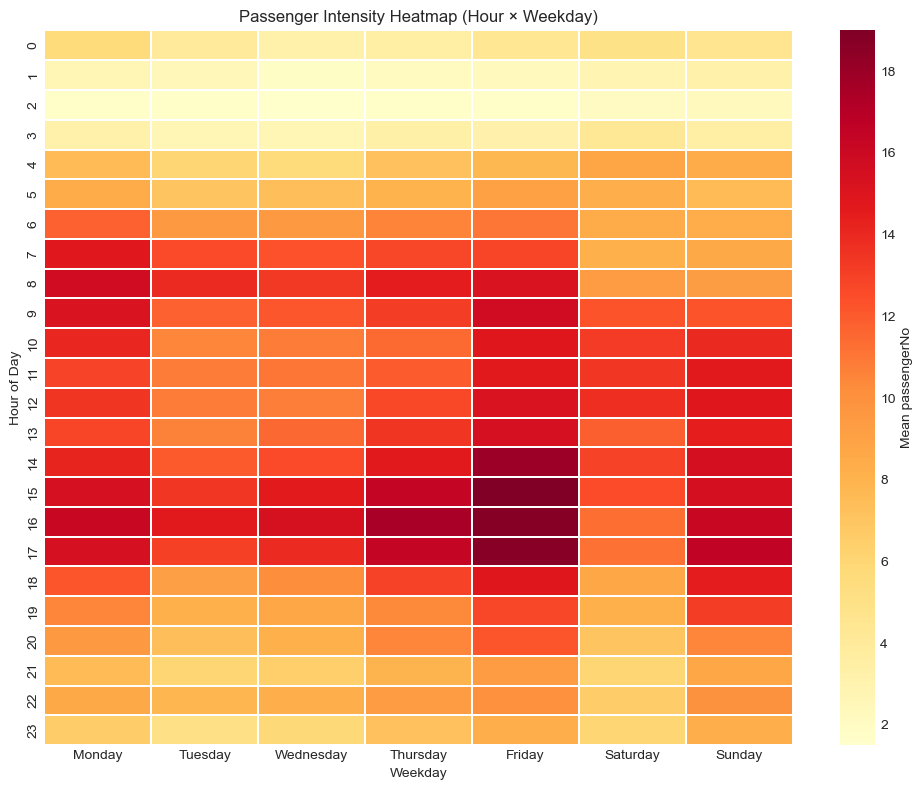

In [10]:
pivot = (
    df.groupby(["hour", "weekday"])["passengerNo"]
    .mean()
    .unstack("weekday")
    .reindex(columns=WEEKDAY_ORDER)
)

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(pivot, ax=ax, cmap="YlOrRd", annot=False, linewidths=0.3, cbar_kws={"label": "Mean passengerNo"})
ax.set_title("Passenger Intensity Heatmap (Hour × Weekday)")
ax.set_xlabel("Weekday")
ax.set_ylabel("Hour of Day")
save(fig, "06_heatmap_hour_weekday.png")
plt.show()

---

## Plot 07 — Net Flow (Arrivals − Departures)

`net_flow = ins − outs` aggregated to daily totals.

- **Green area** (net_flow > 0): more passengers arrived from the airport than departed to it — arrival-dominant day
- **Red area** (net_flow < 0): more passengers departed to the airport than arrived — departure-dominant day

**What to look for:**
- Whether the airport is systematically departure or arrival dominant
- Large swings that might indicate special events or disruptions
- Seasonal shifts in the balance between arrivals and departures

  saved → 07_net_flow.png


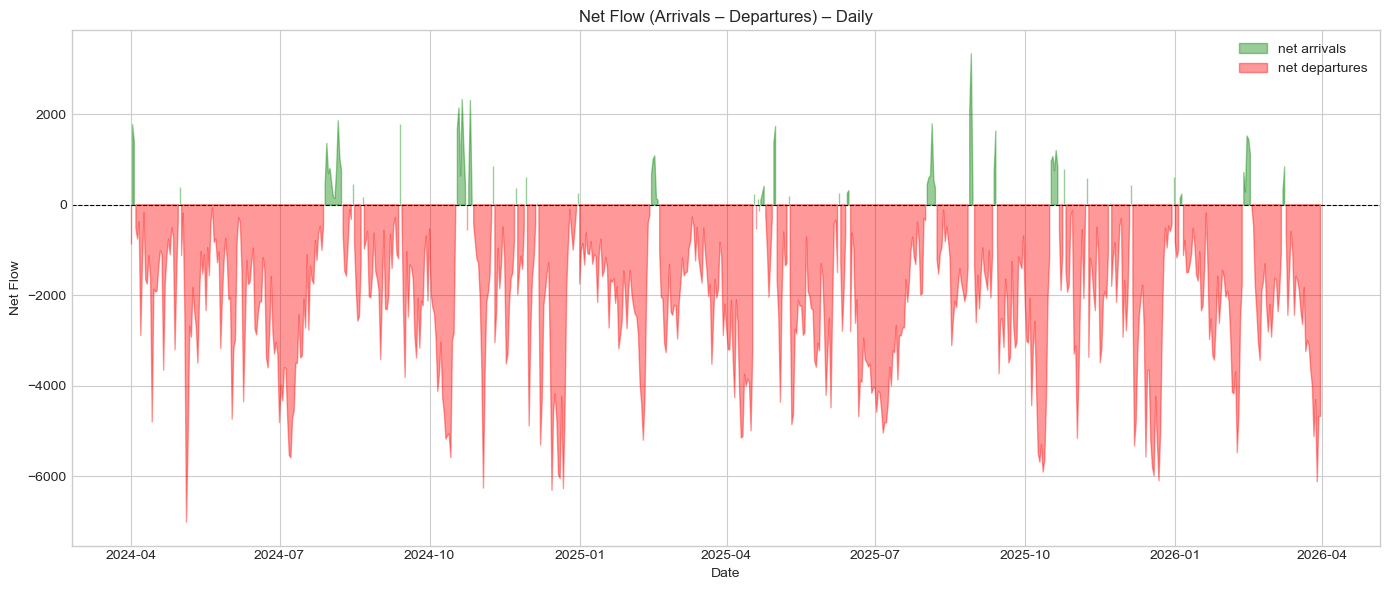

In [11]:
net_daily = df.set_index("timestamp").resample("D")["net_flow"].sum()

fig, ax = plt.subplots(figsize=(14, 6))
ax.fill_between(net_daily.index, net_daily, 0,
                where=net_daily >= 0, color="green", alpha=0.4, label="net arrivals")
ax.fill_between(net_daily.index, net_daily, 0,
                where=net_daily <  0, color="red",   alpha=0.4, label="net departures")
ax.axhline(0, color="black", lw=0.8, ls="--")
ax.set_title("Net Flow (Arrivals – Departures) – Daily")
ax.set_xlabel("Date")
ax.set_ylabel("Net Flow")
ax.legend()
save(fig, "07_net_flow.png")
plt.show()

---

## Plot 08 — Distributions of Ins and Outs

Histogram + KDE of `ins` and `outs` counts (excluding zero observations).

**What to look for:**
- Both distributions are right-skewed (long tail of high-traffic moments)
- `outs` has a heavier tail — confirming its higher variance
- The mean and median are shown as vertical lines. A large gap between them indicates skewness
- This informs our choice of **NegativeBinomial** for the Bayesian model (handles overdispersion better than Poisson)

  saved → 08_distributions.png


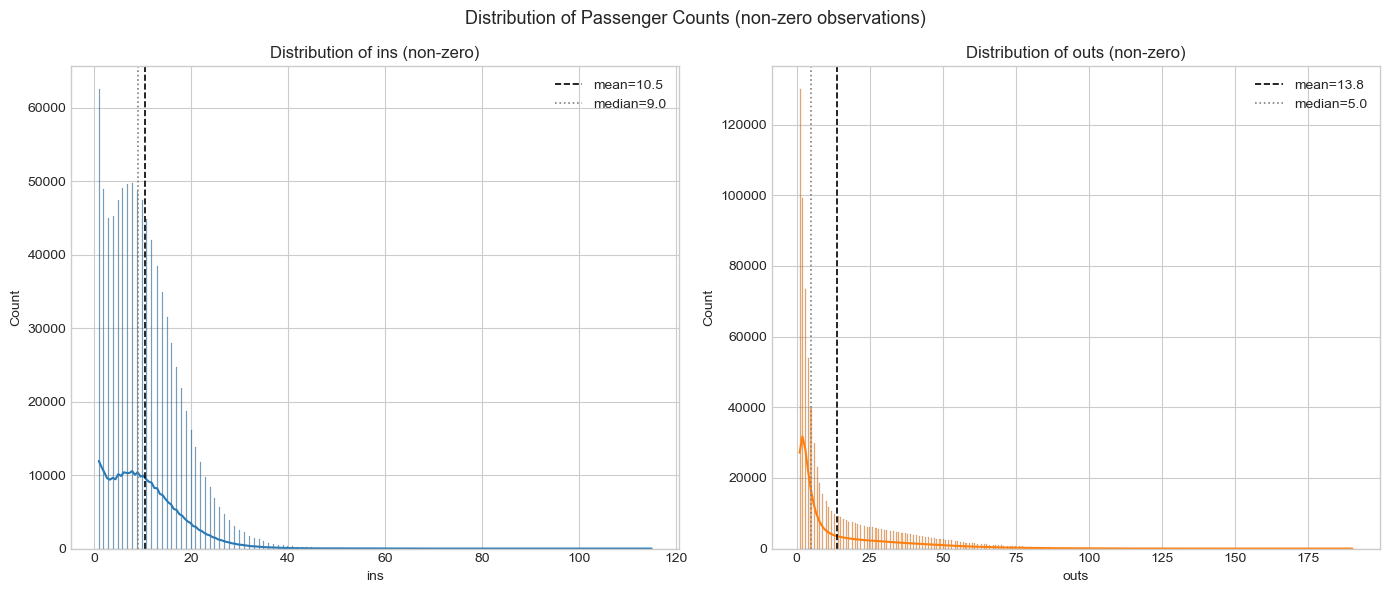

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for ax, col, color in zip(axes, ["ins", "outs"], [BLUE, ORANGE]):
    data = df[df[col] > 0][col]
    sns.histplot(data, kde=True, ax=ax, color=color, alpha=0.6)
    ax.axvline(data.mean(),   color="black", ls="--", lw=1.2, label=f"mean={data.mean():.1f}")
    ax.axvline(data.median(), color="grey",  ls=":",  lw=1.2, label=f"median={data.median():.1f}")
    ax.set_title(f"Distribution of {col} (non-zero)")
    ax.set_xlabel(col)
    ax.legend()

fig.suptitle("Distribution of Passenger Counts (non-zero observations)", fontsize=13)
save(fig, "08_distributions.png")
plt.show()

---

## Plot 09 — 7-Day Rolling Average

Daily totals (faint) overlaid with a **centered 7-day rolling mean** (bold).

The rolling average suppresses day-to-day noise and makes the **trend and seasonal cycle** clearly visible.

**What to look for:**
- Smooth summer peaks and winter troughs
- Whether the trend is growing, flat, or declining year-over-year
- Sharp drops in the rolling average that might indicate multi-day disruptions

  saved → 09_rolling_average.png


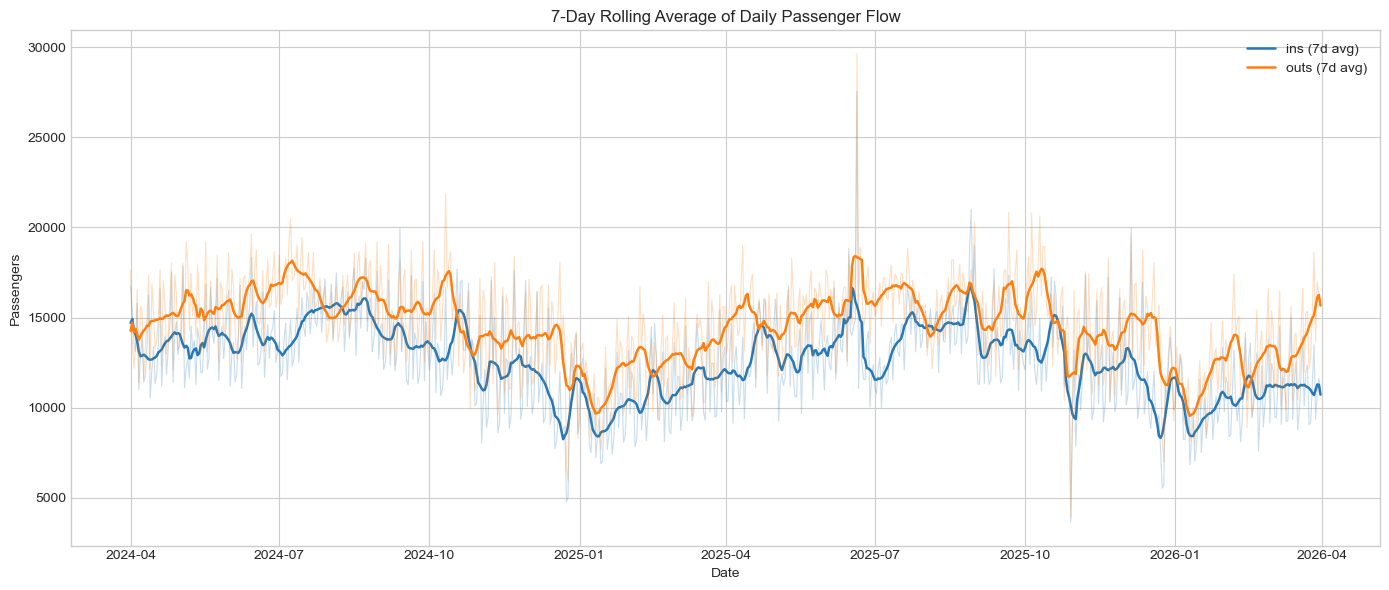

In [13]:
daily_raw = df.set_index("timestamp").resample("D")[["ins", "outs"]].sum()
roll      = daily_raw.rolling(7, center=True, min_periods=1).mean()

fig, ax = plt.subplots(figsize=(14, 6))
for col, color in [("ins", BLUE), ("outs", ORANGE)]:
    ax.plot(daily_raw.index, daily_raw[col], color=color, alpha=0.25, lw=0.8)
    ax.plot(roll.index,      roll[col],      color=color, alpha=1.0,  lw=1.8, label=f"{col} (7d avg)")

ax.set_title("7-Day Rolling Average of Daily Passenger Flow")
ax.set_xlabel("Date")
ax.set_ylabel("Passengers")
ax.legend()
save(fig, "09_rolling_average.png")
plt.show()

---

## Plot 10 — Ins vs Outs Scatter (coloured by hour)

Each dot is one 1-minute observation. The colour encodes the **hour of day** (dark = night, bright = day). The dashed diagonal is `y = x` — points above it are arrival-dominant moments, points below are departure-dominant.

**What to look for:**
- Early morning observations (dark colours) tend to cluster **above** the diagonal — departure-dominant
- Late afternoon (bright colours) tend to cluster **below** — arrival-dominant
- The spread around the diagonal reveals how consistent the directionality is at each hour

  saved → 10_ins_vs_outs_scatter.png


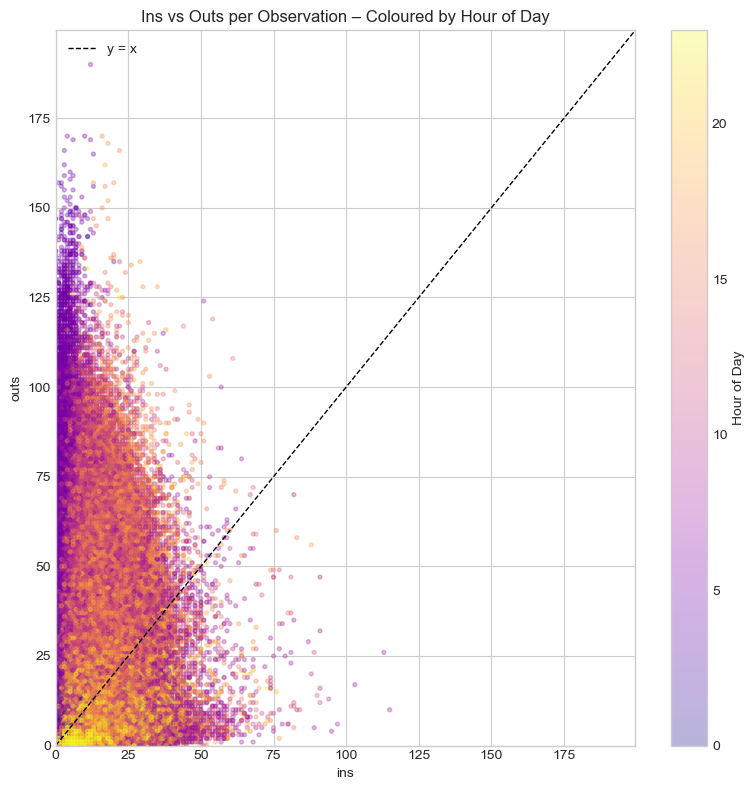

In [14]:
fig, ax = plt.subplots(figsize=(8, 8))
sc = ax.scatter(df["ins"], df["outs"], c=df["hour"], cmap="plasma", alpha=0.3, s=8)
lim = max(df["ins"].max(), df["outs"].max()) * 1.05
ax.plot([0, lim], [0, lim], "k--", lw=1, label="y = x")
ax.set_xlim(0, lim)
ax.set_ylim(0, lim)
fig.colorbar(sc, ax=ax, label="Hour of Day")
ax.set_title("Ins vs Outs per Observation – Coloured by Hour of Day")
ax.set_xlabel("ins")
ax.set_ylabel("outs")
ax.legend()
save(fig, "10_ins_vs_outs_scatter.png")
plt.show()

---

## Plot 11 — Year-over-Year Comparison

Monthly totals for `ins` and `outs` plotted separately for each year in the dataset.

This reveals whether passenger volumes are growing, shrinking, or stable between years, and whether the seasonal shape is consistent.

**What to look for:**
- Is 2025 consistently above or below 2024?
- Do both years show the same summer peak month?
- Any months where the years diverge significantly (could indicate an event or data issue)

  saved → 11_year_over_year.png


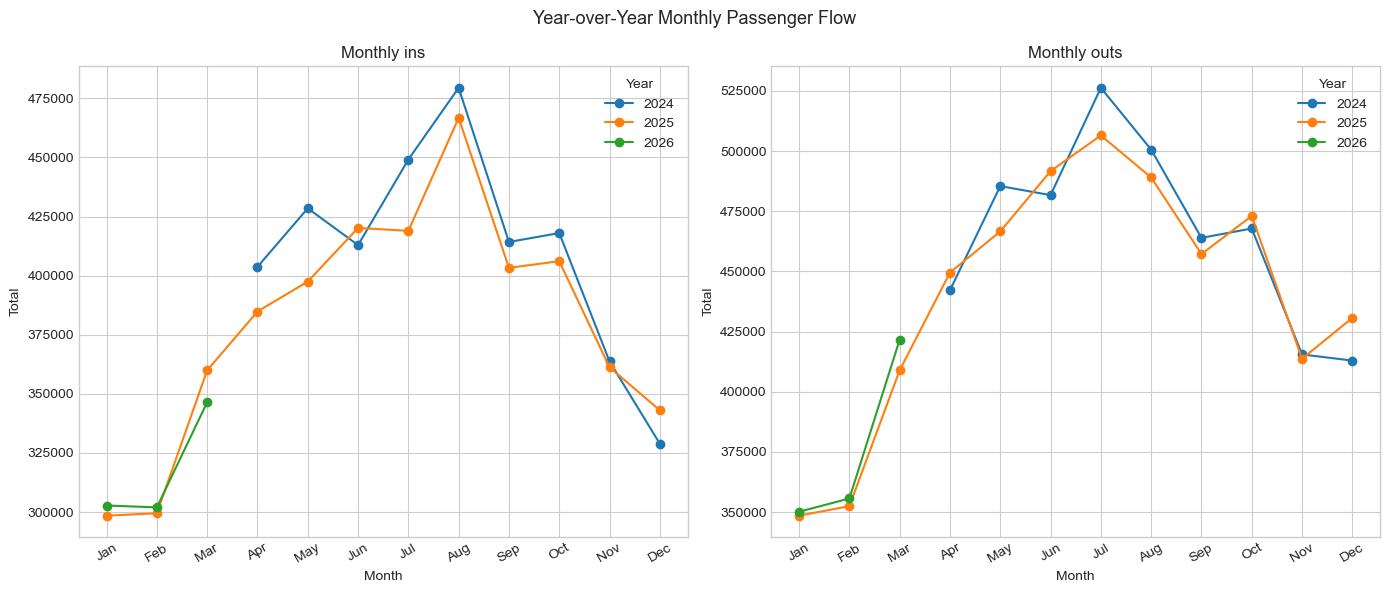

In [15]:
years = sorted(df["year"].unique())

if len(years) < 2:
    print("Fewer than 2 years in data — skipping YoY plot")
else:
    fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=False)
    palette   = plt.cm.tab10.colors

    for ax, col in zip(axes, ["ins", "outs"]):
        for i, yr in enumerate(years):
            sub = df[df["year"] == yr].groupby("month")[col].sum()
            ax.plot(sub.index, sub.values, marker="o",
                    color=palette[i % len(palette)], label=str(yr))
        ax.set_xticks(range(1, 13))
        ax.set_xticklabels(MONTH_NAMES, rotation=30)
        ax.set_title(f"Monthly {col}")
        ax.set_xlabel("Month")
        ax.set_ylabel("Total")
        ax.legend(title="Year")

    fig.suptitle("Year-over-Year Monthly Passenger Flow", fontsize=13)
    save(fig, "11_year_over_year.png")
    plt.show()

---

## Plot 12 — Ins/Outs Ratio Over Time

Daily average of `ins / outs` (a small constant `1e-6` is added to the denominator to avoid division by zero).

- **Ratio > 1** (green): more arrivals than departures on average that day
- **Ratio < 1** (red): more departures than arrivals
- **Ratio = 1** (dashed line): perfect balance

**What to look for:**
- Persistent red periods would suggest the airport is chronically departure-dominant
- Day-to-day flipping between red and green is normal
- Large sustained swings might indicate special events (festivals, disruptions)

  saved → 12_ratio_over_time.png


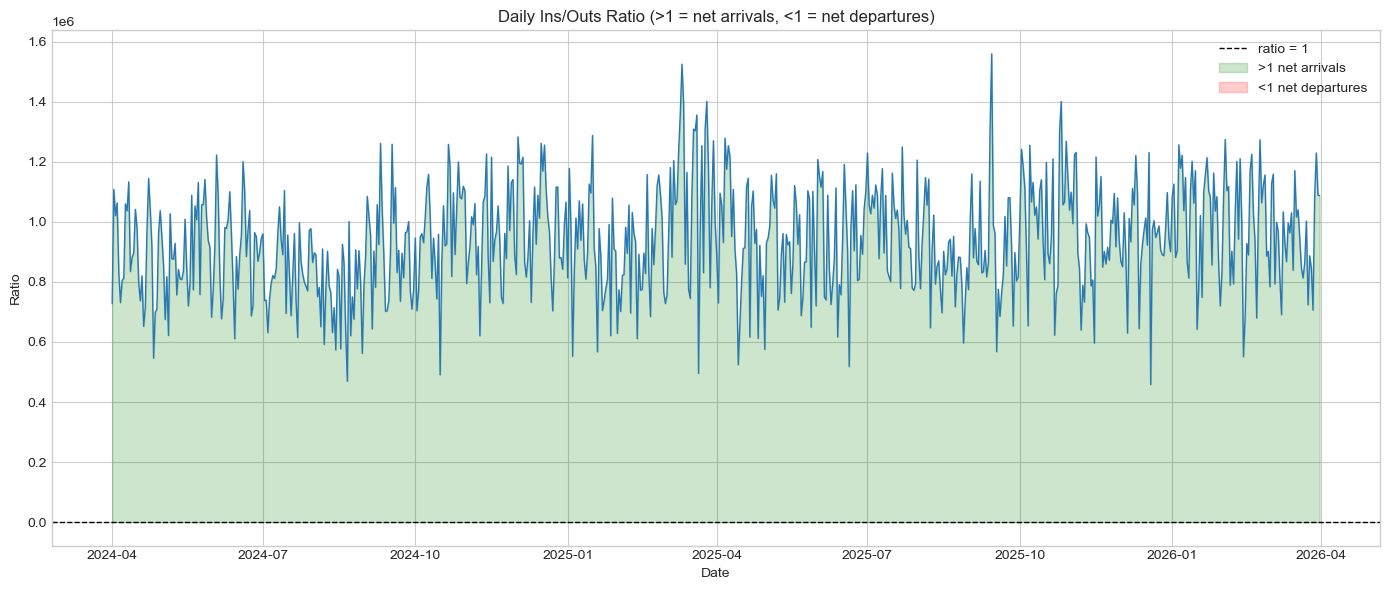

In [16]:
df["ratio"]  = df["ins"] / (df["outs"] + 1e-6)
ratio_daily  = df.set_index("timestamp").resample("D")["ratio"].mean()

fig, ax = plt.subplots(figsize=(14, 6))
ax.plot(ratio_daily.index, ratio_daily, color=BLUE, lw=1.0)
ax.axhline(1.0, color="black", ls="--", lw=1, label="ratio = 1")
ax.fill_between(ratio_daily.index, ratio_daily, 1,
                where=ratio_daily >= 1, color="green", alpha=0.2, label=">1 net arrivals")
ax.fill_between(ratio_daily.index, ratio_daily, 1,
                where=ratio_daily <  1, color="red",   alpha=0.2, label="<1 net departures")
ax.set_title("Daily Ins/Outs Ratio (>1 = net arrivals, <1 = net departures)")
ax.set_xlabel("Date")
ax.set_ylabel("Ratio")
ax.legend()
save(fig, "12_ratio_over_time.png")
plt.show()

---

## Plot 13 — Outlier Detection

We aggregate to daily totals and compute **z-scores** for both `ins` and `outs`. A day is flagged as an outlier if either z-score exceeds ±2.5 (i.e., more than 2.5 standard deviations from the mean).

Outliers are shown as **red dots** on the time series.

**What to look for:**
- Extreme highs: special events, concerts, matches near the airport line
- Extreme lows: service disruptions, strikes, severe weather
- The top 10 anomalous days are printed below the plot

  saved → 13_outliers.png


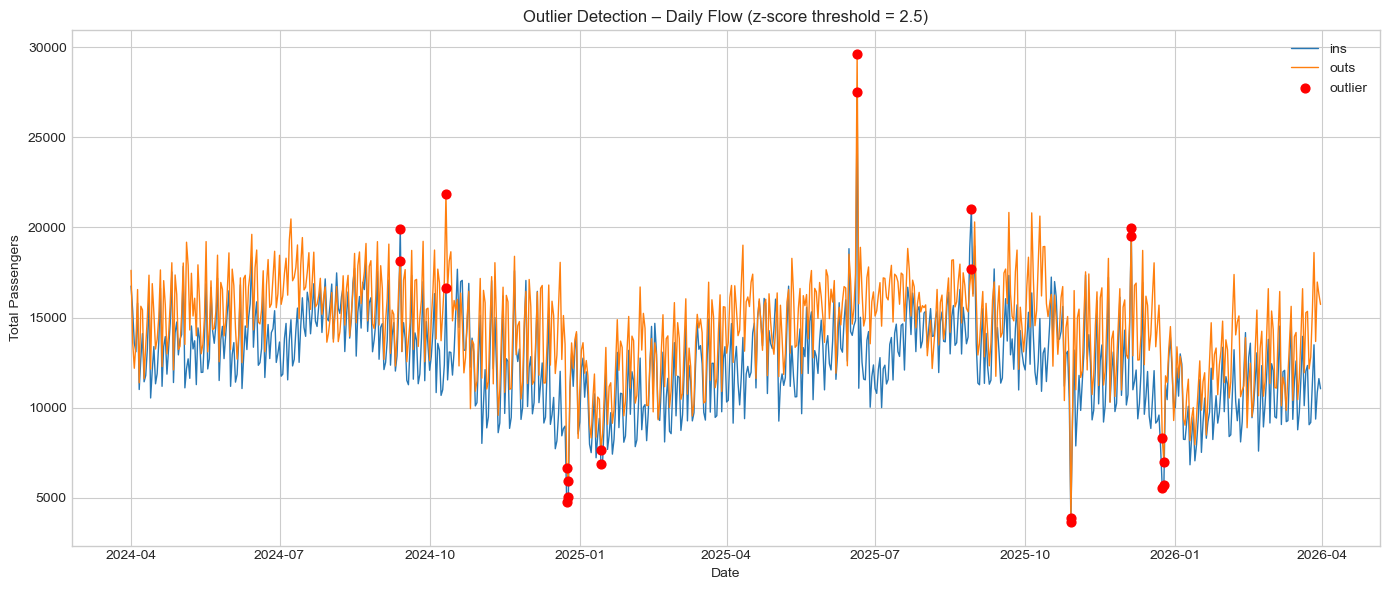


Top 10 anomalous dates:


,ins,outs,z_ins,z_outs
timestamp,,,,
2025-06-20 00:00:00+00:00,27531.0,29630.0,5.700432,5.631622
2025-10-29 00:00:00+00:00,3648.0,3903.0,-3.427406,-3.967697
2024-12-25 00:00:00+00:00,5030.0,5939.0,-2.899220,-3.208020
2025-08-29 00:00:00+00:00,21004.0,17671.0,3.205879,1.169452
2024-12-24 00:00:00+00:00,4786.0,6675.0,-2.992474,-2.933401
2025-12-25 00:00:00+00:00,5699.0,6961.0,-2.643535,-2.826688
2025-12-05 00:00:00+00:00,19966.0,19533.0,2.809166,1.864206
2024-09-13 00:00:00+00:00,19926.0,18152.0,2.793879,1.348924
2024-10-11 00:00:00+00:00,16663.0,21838.0,1.546794,2.724253


In [17]:
daily_out = df.set_index("timestamp").resample("D")[["ins", "outs"]].sum()

for col in ["ins", "outs"]:
    daily_out[f"z_{col}"] = stats.zscore(daily_out[col].fillna(0))

daily_out["is_outlier"] = (daily_out["z_ins"].abs() > 2.5) | (daily_out["z_outs"].abs() > 2.5)

fig, ax = plt.subplots(figsize=(14, 6))
ax.plot(daily_out.index, daily_out["ins"],  color=BLUE,   lw=1.0, label="ins")
ax.plot(daily_out.index, daily_out["outs"], color=ORANGE, lw=1.0, label="outs")

outlier_days = daily_out[daily_out["is_outlier"]]
ax.scatter(outlier_days.index, outlier_days["ins"],  color="red", zorder=5, s=40, label="outlier")
ax.scatter(outlier_days.index, outlier_days["outs"], color="red", zorder=5, s=40)

ax.set_title("Outlier Detection – Daily Flow (z-score threshold = 2.5)")
ax.set_xlabel("Date")
ax.set_ylabel("Total Passengers")
ax.legend()
save(fig, "13_outliers.png")
plt.show()

top10 = (
    daily_out[daily_out["is_outlier"]][["ins", "outs", "z_ins", "z_outs"]]
    .assign(max_z=lambda x: x[["z_ins", "z_outs"]].abs().max(axis=1))
    .sort_values("max_z", ascending=False)
    .head(10)
)
print("\nTop 10 anomalous dates:")
top10[["ins", "outs", "z_ins", "z_outs"]]

---

## Plot 14 — Cumulative Flow

The running cumulative total of `ins` and `outs` over the full 2-year period.

**What to look for:**
- The slope of each line represents the instantaneous throughput rate — steeper = more passengers
- The gap between the two lines tells you the cumulative balance: which direction has processed more passengers in total
- Any flattening of either curve (slope → 0) would indicate a period of near-zero activity

  saved → 14_cumulative_flow.png


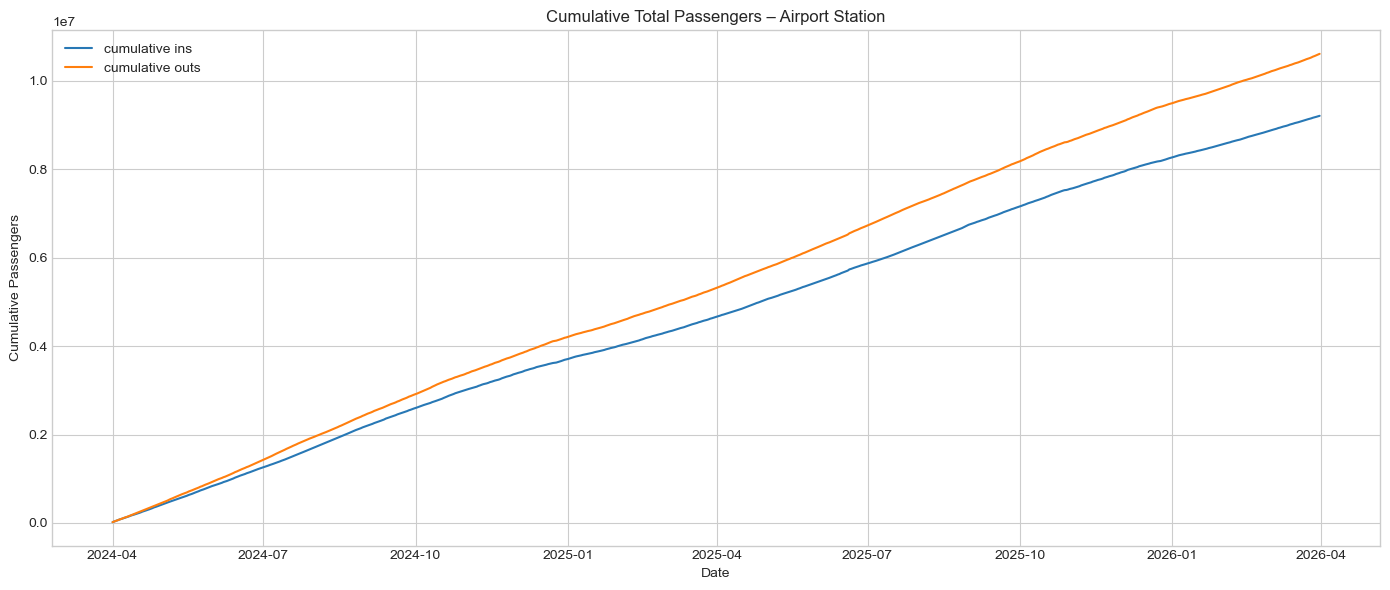

In [18]:
daily_cum = df.set_index("timestamp").resample("D")[["ins", "outs"]].sum().cumsum()

fig, ax = plt.subplots(figsize=(14, 6))
ax.plot(daily_cum.index, daily_cum["ins"],  color=BLUE,   lw=1.5, label="cumulative ins")
ax.plot(daily_cum.index, daily_cum["outs"], color=ORANGE, lw=1.5, label="cumulative outs")
ax.set_title("Cumulative Total Passengers – Airport Station")
ax.set_xlabel("Date")
ax.set_ylabel("Cumulative Passengers")
ax.legend()
save(fig, "14_cumulative_flow.png")
plt.show()

---

## Summary

| Finding | Detail |
|---|---|
| Peak departure hour | 06:00 (morning wave) and 16:00 (afternoon wave) |
| Peak arrival hour | 17:00 |
| Busiest weekday | Friday |
| Busiest month | August |
| Seasonal swing | ~+46% August vs January |
| `passengerNo` | Exactly `(ins + outs) / 2` — no extra information |
| Distribution shape | Right-skewed, overdispersed — motivates NegativeBinomial in the Bayesian model |
| Largest anomaly | 2025-06-20 (z-score 5.7) — cause unknown |

All 14 plots are saved in `output_plots/`.